# importing the libraries #

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from plotly import express as px
import seaborn as sns

%matplotlib inline
pd.set_option('display.max.columns', None)
pd.set_option('display.max.rows', 150)
sns.set_style('darkgrid')
plt.rcParams['font.size'] = 14
plt.rcParams['figure.figsize'] = (10,6)
plt.rcParams['figure.facecolor'] = '#00000000'

# importing the datasets #

In [2]:
train_df = pd.read_csv('train.csv')

In [3]:
raw_test_df = pd.read_csv('test.csv')

In [4]:
train_df.head()

,User ID,Mobile No.,User DOB,User Job,Duration,Intl_Plan,Voicemail_Plan,Voicemail_Messages,Day_Minutes,Day_Calls,Day_Charge,Eve_Minutes,Eve_Calls,Eve_Charge,Night_Minutes,Night_Calls,Night_Charge,Intl_Minutes,Intl_Calls,Intl_Charge,Service_Calls,Attrition
0,3487,6537028081,1969-07-18,Television camera operator,40,no,no,0.0,309.4,86.0,683.80,271.3,98,299.78,197.1,116,115.31,11.2,5,39.26,3,Yes
1,3488,9399737812,1981-08-04,Quarry manager,161,no,no,0.0,159.6,102.0,352.69,212.6,119,234.91,151.4,83,88.53,12.6,7,NaN,5,Yes
2,3495,9496493681,2002-10-12,Dispensing optician,69,yes,no,0.0,176.8,NaN,390.78,196.0,89,216.58,232.6,151,136.11,13.1,5,NaN,1,Yes
3,3499,7741629385,1976-06-07,Production manager,114,yes,no,0.0,115.6,93.0,255.45,NaN,78,180.31,251.3,104,147.03,9.7,1,34.06,2,Yes
4,3526,8157186467,1957-03-20,"Designer, industrial/product",104,NaN,no,0.0,261.2,81.0,577.20,209.1,130,231.01,281.1,121,164.45,11.3,1,39.65,2,Yes


In [5]:
raw_test_df.head()

,User ID,Mobile No.,User DOB,User Job,Duration,Intl_Plan,Voicemail_Plan,Voicemail_Messages,Day_Minutes,Day_Calls,Day_Charge,Eve_Minutes,Eve_Calls,Eve_Charge,Night_Minutes,Night_Calls,Night_Charge,Intl_Minutes,Intl_Calls,Intl_Charge,Service_Calls
0,11,7042019355,2003-05-09,Clinical molecular geneticist,65,no,no,0,129.1,137,285.35,228.5,83,252.46,208.8,111,122.20,12.7,6,44.59,4
1,16,8512321378,1958-06-19,Control and instrumentation engineer,161,no,no,0,332.9,67,735.67,317.8,97,351.13,160.6,128,93.99,5.4,9,18.98,4
2,22,6637930066,1964-03-15,Osteopath,77,no,no,0,62.4,89,137.93,169.9,121,187.72,209.6,64,122.59,5.7,6,20.02,5
3,34,6835517293,1949-08-19,"Engineer, civil (contracting)",12,no,no,0,249.6,118,551.59,252.4,119,278.85,280.2,90,163.93,11.8,3,41.47,1
4,42,6337364996,1970-12-10,Equities trader,135,yes,yes,41,173.1,85,382.59,203.9,107,225.29,122.2,78,71.50,14.6,15,51.22,0


In [6]:
raw_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   User ID             850 non-null    int64  
 1   Mobile No.          850 non-null    int64  
 2   User DOB            850 non-null    str    
 3   User Job            850 non-null    str    
 4   Duration            850 non-null    int64  
 5   Intl_Plan           850 non-null    str    
 6   Voicemail_Plan      850 non-null    str    
 7   Voicemail_Messages  850 non-null    int64  
 8   Day_Minutes         850 non-null    float64
 9   Day_Calls           850 non-null    int64  
 10  Day_Charge          850 non-null    float64
 11  Eve_Minutes         850 non-null    float64
 12  Eve_Calls           850 non-null    int64  
 13  Eve_Charge          850 non-null    float64
 14  Night_Minutes       850 non-null    float64
 15  Night_Calls         850 non-null    int64  
 16  Night_Charge       

# dropping unwanted columns #
- its important to drop all unnecessary columns that do not provide any useful information for training the model

In [7]:
train_df.drop(['User ID','Mobile No.'],axis = 1 ,inplace = True)

In [8]:
test_df = raw_test_df.drop(['User ID','Mobile No.'],axis = 1)

# dropping duplicated columns #

In [9]:
train_df.duplicated().sum()

np.int64(0)

In [10]:
test_df.duplicated().sum()

np.int64(0)

our datasets doesnot have any duplicated columns hence we skip this step

# Exploratory data analysis #

In [11]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4150 entries, 0 to 4149
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   User DOB            4150 non-null   str    
 1   User Job            4150 non-null   str    
 2   Duration            4150 non-null   int64  
 3   Intl_Plan           3679 non-null   str    
 4   Voicemail_Plan      4150 non-null   str    
 5   Voicemail_Messages  3681 non-null   float64
 6   Day_Minutes         4150 non-null   float64
 7   Day_Calls           3640 non-null   float64
 8   Day_Charge          4150 non-null   float64
 9   Eve_Minutes         3626 non-null   float64
 10  Eve_Calls           4150 non-null   int64  
 11  Eve_Charge          4150 non-null   float64
 12  Night_Minutes       3548 non-null   float64
 13  Night_Calls         4150 non-null   int64  
 14  Night_Charge        4150 non-null   float64
 15  Intl_Minutes        4150 non-null   float64
 16  Intl_Calls       

## identifying input features and targets ##

In [12]:
train_df.columns

Index(['User DOB', 'User Job', 'Duration', 'Intl_Plan', 'Voicemail_Plan',
       'Voicemail_Messages', 'Day_Minutes', 'Day_Calls', 'Day_Charge',
       'Eve_Minutes', 'Eve_Calls', 'Eve_Charge', 'Night_Minutes',
       'Night_Calls', 'Night_Charge', 'Intl_Minutes', 'Intl_Calls',
       'Intl_Charge', 'Service_Calls', 'Attrition'],
      dtype='str')

In [13]:
input_cols = ['User DOB', 'User Job', 'Duration', 'Intl_Plan', 'Voicemail_Plan',
       'Voicemail_Messages', 'Day_Minutes', 'Day_Calls', 'Day_Charge',
       'Eve_Minutes', 'Eve_Calls', 'Eve_Charge', 'Night_Minutes',
       'Night_Calls', 'Night_Charge', 'Intl_Minutes', 'Intl_Calls',
       'Intl_Charge', 'Service_Calls']

In [14]:
target_col = 'Attrition'

In [15]:
train_df[target_col].isna().sum()

np.int64(0)

In [16]:
train_df[target_col].value_counts()

Attrition
No     3943
Yes     207
Name: count, dtype: int64

<Axes: title={'center': 'Distribution of the target(Attrition) column'}, xlabel='Attrition', ylabel='count'>

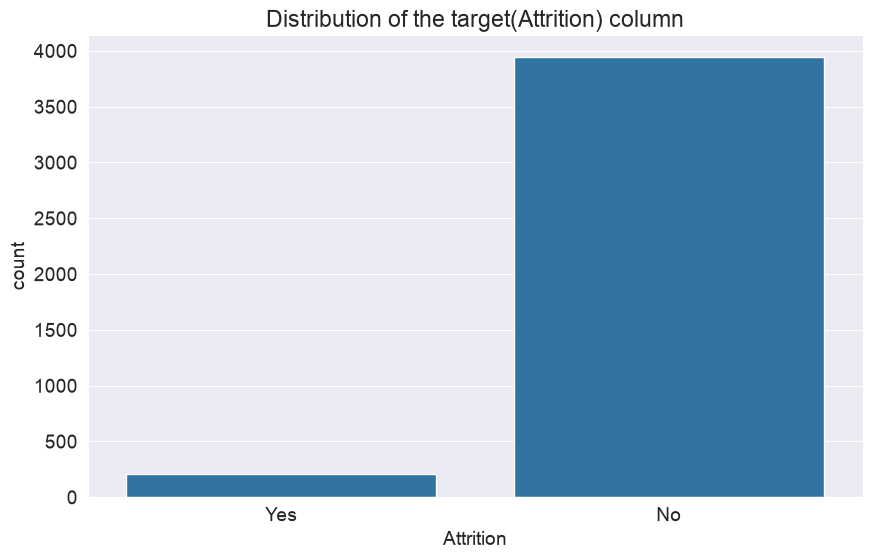

In [17]:
plt.title('Distribution of the target(Attrition) column')
sns.countplot(train_df,x = 'Attrition')

our target column is highly imbalanced with 'No' class having 19 times more values than the 'Yes' column 

## identifying numerical and categorical columns ##

In [18]:
numerical = train_df[input_cols].select_dtypes(include = np.number).columns.to_list()
print('there are {} numerical variables(columns) in the datasets'.format(len(numerical)))

there are 15 numerical variables(columns) in the datasets


In [19]:
categorical = train_df[input_cols].select_dtypes(['str','object']).columns.to_list()
print('there are {} categorical variables(columns) in the datasets'.format(len(categorical)))

there are 4 categorical variables(columns) in the datasets


## Engineering of categorical columns ##

In [20]:
train_df[categorical]

,User DOB,User Job,Intl_Plan,Voicemail_Plan
0,1969-07-18,Television camera operator,no,no
1,1981-08-04,Quarry manager,no,no
2,2002-10-12,Dispensing optician,yes,no
3,1976-06-07,Production manager,yes,no
4,1957-03-20,"Designer, industrial/product",NaN,no
...,...,...,...,...
4145,1970-05-12,"Scientist, research (physical sciences)",no,no
4146,1974-09-28,Community education officer,NaN,yes
4147,1994-03-20,Industrial/product designer,no,no
4148,2005-06-17,Phytotherapist,no,no


### 1. User DOB column ###

from this column we can determine Age of a user using simple mathematical calculations, the age of a user can give us a useful information on which age group of customers are likely to do attrition

In [21]:
train_df.rename(columns = {'User DOB':'DOB'}, inplace = True)

In [22]:
train_df['DOB'] = pd.to_datetime(train_df['DOB'])

In [23]:
train_df['DOB'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: DOB
Non-Null Count  Dtype         
--------------  -----         
4150 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 32.6 KB


In [24]:
train_df['DOB'] = train_df['DOB'].dt.year

In [25]:
train_df['Age'] = train_df['DOB'].apply(lambda x:2026-x)  

In [26]:
train_df.drop('DOB', axis = 1, inplace = True)

In [27]:
train_df

,User Job,Duration,Intl_Plan,Voicemail_Plan,Voicemail_Messages,Day_Minutes,Day_Calls,Day_Charge,Eve_Minutes,Eve_Calls,Eve_Charge,Night_Minutes,Night_Calls,Night_Charge,Intl_Minutes,Intl_Calls,Intl_Charge,Service_Calls,Attrition,Age
0,Television camera operator,40,no,no,0.0,309.4,86.0,683.80,271.3,98,299.78,197.1,116,115.31,11.2,5,39.26,3,Yes,57
1,Quarry manager,161,no,no,0.0,159.6,102.0,352.69,212.6,119,234.91,151.4,83,88.53,12.6,7,NaN,5,Yes,45
2,Dispensing optician,69,yes,no,0.0,176.8,NaN,390.78,196.0,89,216.58,232.6,151,136.11,13.1,5,NaN,1,Yes,24
3,Production manager,114,yes,no,0.0,115.6,93.0,255.45,NaN,78,180.31,251.3,104,147.03,9.7,1,34.06,2,Yes,50
4,"Designer, industrial/product",104,NaN,no,0.0,261.2,81.0,577.20,209.1,130,231.01,281.1,121,164.45,11.3,1,39.65,2,Yes,69
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4145,"Scientist, research (physical sciences)",75,no,no,0.0,170.7,101.0,377.26,193.1,126,213.33,129.1,104,75.53,6.9,7,NaN,1,No,56
4146,Community education officer,50,NaN,yes,40.0,235.7,127.0,520.91,NaN,126,246.48,297.5,116,174.07,9.9,5,NaN,2,No,52
4147,Industrial/product designer,61,no,no,0.0,140.6,89.0,310.70,172.8,128,190.97,212.4,97,124.28,13.6,4,47.71,1,No,32
4148,Phytotherapist,109,no,no,0.0,188.8,67.0,417.30,171.7,92,189.67,224.4,89,131.30,8.5,6,29.90,0,No,21


In [28]:
train_df.Age.describe()

count    4150.000000
mean       52.422410
std        18.527269
min        21.000000
25%        36.000000
50%        52.000000
75%        69.000000
max        84.000000
Name: Age, dtype: float64

we can see the minimum age is 18 and the maximum age is 84 and this makes sense also data is distributed normally since the values seems to be concetrated towards the mean

Text(0.5, 1.0, 'Distribution of Age column due to Attrition status')

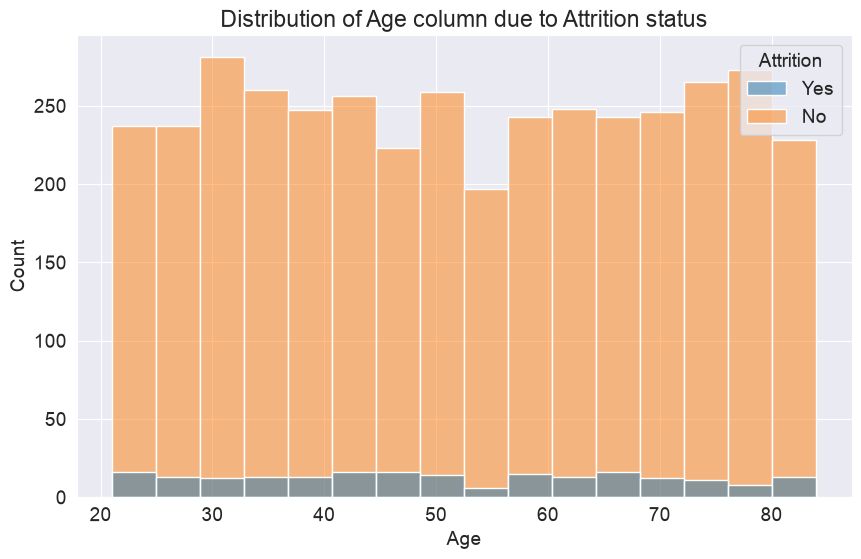

In [29]:
sns.histplot(train_df,x='Age',hue='Attrition')
plt.title('Distribution of Age column due to Attrition status')

we can see from the histogram that number of users who did Attrition based on their Age is fairly distributed across the dataset

In [30]:
test_df.rename(columns = {'User DOB':'DOB'}, inplace = True)
test_df['DOB'] = pd.to_datetime(test_df['DOB'])
test_df['DOB'] = test_df['DOB'].dt.year
test_df['Age'] = test_df['DOB'].apply(lambda x:2026-x)  
test_df.drop('DOB', axis = 1, inplace = True)

### 2. User Job Column ###

first, we need to change the name of the column from 'User Job' to 'Job' for easy fetching of the data

In [31]:
train_df.rename(columns = {'User Job':'Job'}, inplace = True)

In [32]:
train_df['Job']

0                    Television camera operator
1                                Quarry manager
2                           Dispensing optician
3                            Production manager
4                  Designer, industrial/product
                         ...                   
4145    Scientist, research (physical sciences)
4146                Community education officer
4147                Industrial/product designer
4148                             Phytotherapist
4149                                        Sub
Name: Job, Length: 4150, dtype: str

we can see the 'Job' column has inconsistent formatting due to presence of special characters in the values of the column, we need to remove these characters to ensure data is stored consistently

In [33]:
train_df['Job'] = train_df['Job'].str.replace(',','')

In [34]:
train_df['Job'] = train_df['Job'].str.replace(
    r'[^a-zA-Z0-9 ]', ' ', regex=True
)

In [35]:
train_df['Job']

0                   Television camera operator
1                               Quarry manager
2                          Dispensing optician
3                           Production manager
4                  Designer industrial product
                         ...                  
4145    Scientist research  physical sciences 
4146               Community education officer
4147               Industrial product designer
4148                            Phytotherapist
4149                                       Sub
Name: Job, Length: 4150, dtype: str

In [36]:
train_df['Job'] = train_df['Job'].str.strip()

In [37]:
train_df['Job'].nunique()

638

we can see that the cleaned user job column has very high cardinality(number of labels), due to this factor we will drop the column since it will lead to presence of very high number of features during the encoding process

In [38]:
test_df.rename(columns = {'User Job':'Job'}, inplace = True)
test_df['Job'] = test_df['Job'].str.replace(',','')
test_df['Job'] = test_df['Job'].str.replace(
    r'[^a-zA-Z0-9 ]', ' ', regex=True)
test_df['Job'] = test_df['Job'].str.strip()

### 3. Intl_Plan column ###

In [39]:
train_df['Intl_Plan'].unique()

<ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str

In [40]:
# checking cardinality of the international plan column
train_df['Intl_Plan'].nunique()

2

Text(0.5, 1.0, 'distribution of international plan users')

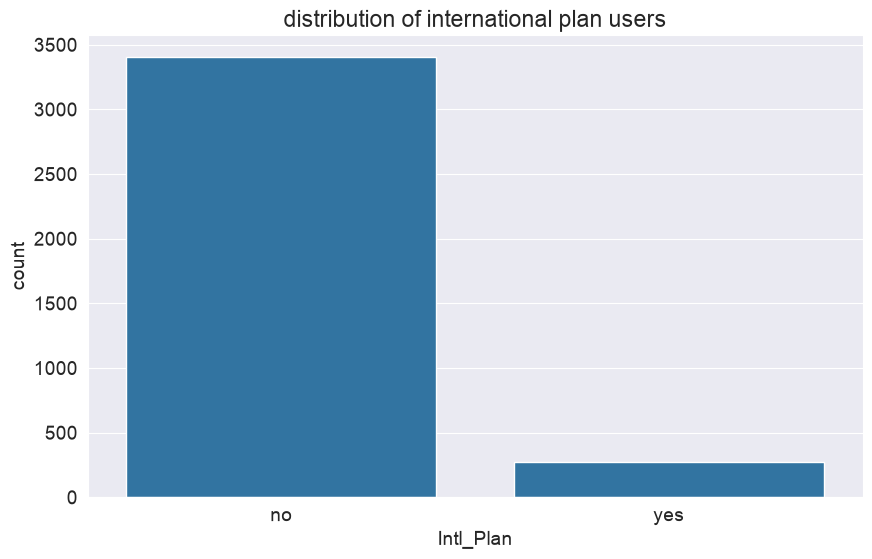

In [41]:
sns.barplot(data=train_df['Intl_Plan'].value_counts())
plt.title('distribution of international plan users')

In [42]:
train_df['Intl_Plan'].isna().sum()

np.int64(471)

In [43]:
per = (train_df['Intl_Plan'].isna().sum()/4150)*100

the international plan columns has total of 471 missing values which is equal to of all values

In [44]:
train_df['Intl_Plan'].mode()[0]

'no'

In [45]:
train_df['Intl_Plan'] = train_df['Intl_Plan'].fillna(train_df['Intl_Plan'].mode()[0])

In [46]:
train_df['Intl_Plan'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Intl_Plan
Non-Null Count  Dtype
--------------  -----
4150 non-null   str  
dtypes: str(1)
memory usage: 40.9 KB


### 4. Voicemail_Plan column ###

In [47]:
train_df['Voicemail_Plan'].unique()

<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

In [48]:
train_df['Voicemail_Plan'].nunique()

2

In [49]:
train_df['Voicemail_Plan'].value_counts()

Voicemail_Plan
no     3004
yes    1146
Name: count, dtype: int64

Text(0.5, 1.0, 'distribution of voicemail plan users')

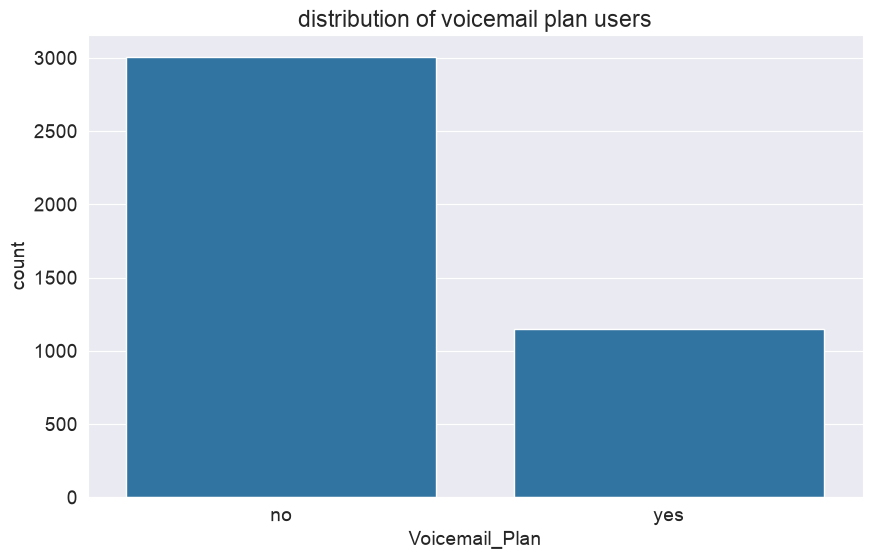

In [50]:
sns.barplot(data=train_df['Voicemail_Plan'].value_counts())
plt.title('distribution of voicemail plan users')

In [51]:
train_df['Voicemail_Plan'].isna().sum()

np.int64(0)

## Engineering of numerical columns ##

In [52]:
train_df[numerical]

,Duration,Voicemail_Messages,Day_Minutes,Day_Calls,Day_Charge,Eve_Minutes,Eve_Calls,Eve_Charge,Night_Minutes,Night_Calls,Night_Charge,Intl_Minutes,Intl_Calls,Intl_Charge,Service_Calls
0,40,0.0,309.4,86.0,683.80,271.3,98,299.78,197.1,116,115.31,11.2,5,39.26,3
1,161,0.0,159.6,102.0,352.69,212.6,119,234.91,151.4,83,88.53,12.6,7,NaN,5
2,69,0.0,176.8,NaN,390.78,196.0,89,216.58,232.6,151,136.11,13.1,5,NaN,1
3,114,0.0,115.6,93.0,255.45,NaN,78,180.31,251.3,104,147.03,9.7,1,34.06,2
4,104,0.0,261.2,81.0,577.20,209.1,130,231.01,281.1,121,164.45,11.3,1,39.65,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4145,75,0.0,170.7,101.0,377.26,193.1,126,213.33,129.1,104,75.53,6.9,7,NaN,1
4146,50,40.0,235.7,127.0,520.91,NaN,126,246.48,297.5,116,174.07,9.9,5,NaN,2
4147,61,0.0,140.6,89.0,310.70,172.8,128,190.97,212.4,97,124.28,13.6,4,47.71,1
4148,109,0.0,188.8,67.0,417.30,171.7,92,189.67,224.4,89,131.30,8.5,6,29.90,0


### 1. Duration column ###

In [53]:
train_df['Duration'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Duration
Non-Null Count  Dtype
--------------  -----
4150 non-null   int64
dtypes: int64(1)
memory usage: 32.6 KB


In [54]:
train_df['Duration'].describe()

count    4150.000000
mean       99.967470
std        39.816089
min         1.000000
25%        73.000000
50%       100.000000
75%       127.000000
max       243.000000
Name: Duration, dtype: float64

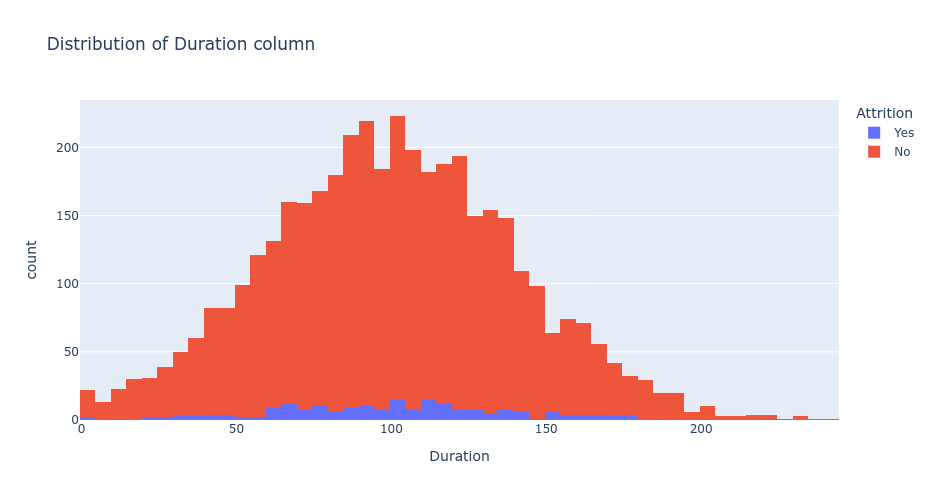

In [55]:
px.histogram(train_df,x='Duration',
             color = 'Attrition',
             title='Distribution of Duration column',
            width = 800,height=500)

Text(0.5, 1.0, 'Distribution of Duration ')

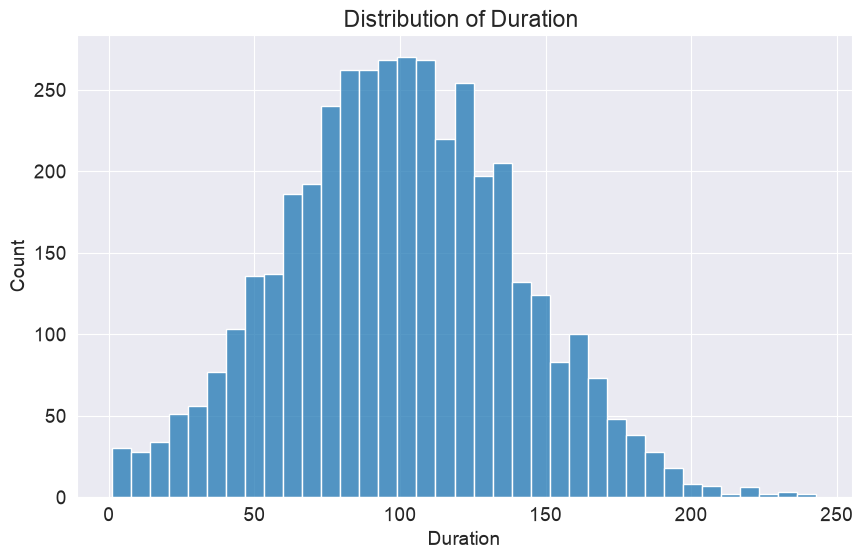

In [56]:
sns.histplot(data=train_df['Duration'])
plt.title('Distribution of Duration ')

from the histogram we can see that the Duration column is normally distributed

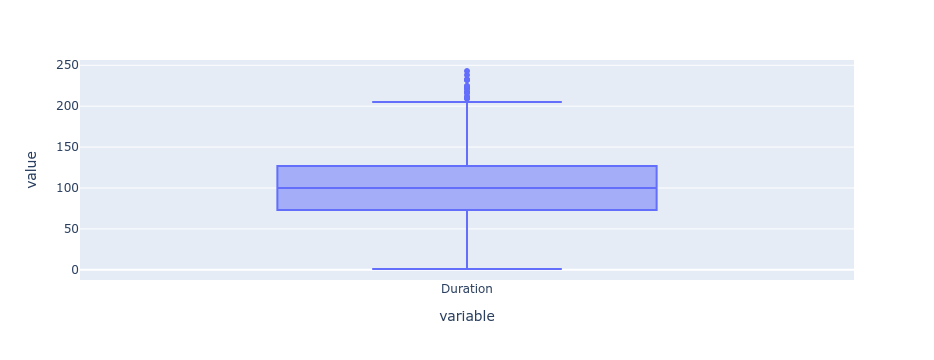

In [57]:
px.box(train_df['Duration'])

from the graph, we can see that there are potential outliers but that doesnot conclude that we can engineer the outliers since a person can talk to phone more than average hence it doesnt provide much information to remove them

### 2. Voicemail_Messages column ###

In [58]:
train_df['Voicemail_Messages'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Voicemail_Messages
Non-Null Count  Dtype  
--------------  -----  
3681 non-null   float64
dtypes: float64(1)
memory usage: 32.6 KB


In [59]:
train_df['Voicemail_Messages'].describe()

count    3681.000000
mean        7.890519
std        13.599601
min         0.000000
25%         0.000000
50%         0.000000
75%        18.000000
max        52.000000
Name: Voicemail_Messages, dtype: float64

Text(0.5, 1.0, 'Distribution of Voicemail Messages')

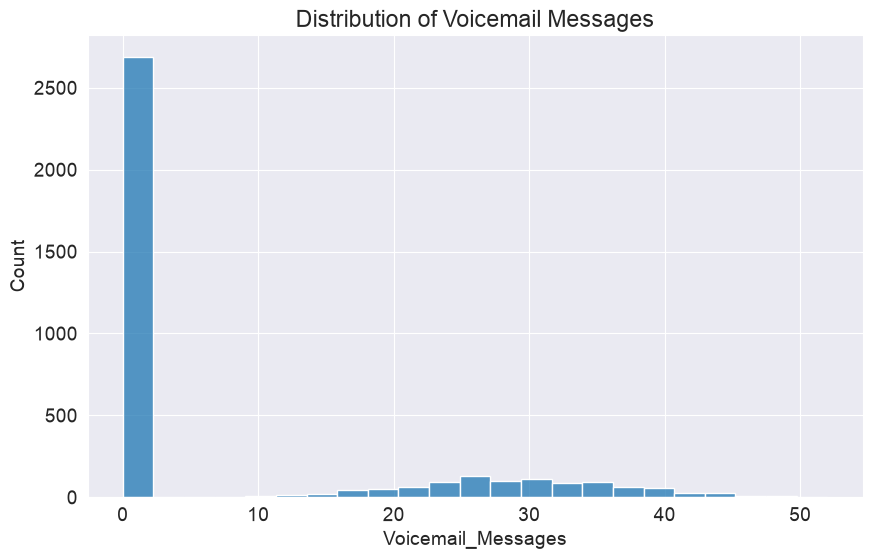

In [60]:
sns.histplot(data=train_df['Voicemail_Messages'])
plt.title('Distribution of Voicemail Messages')

In [61]:
train_df['Voicemail_Messages'].value_counts()

Voicemail_Messages
0.0     2686
31.0      65
29.0      50
27.0      50
24.0      49
33.0      47
28.0      46
30.0      44
26.0      43
32.0      42
23.0      41
25.0      39
39.0      37
34.0      34
22.0      34
38.0      31
37.0      31
35.0      30
21.0      29
36.0      29
20.0      25
19.0      23
40.0      22
17.0      18
16.0      13
41.0      12
18.0      12
43.0      12
42.0      12
15.0      10
45.0       9
14.0       9
12.0       8
46.0       6
44.0       6
47.0       4
48.0       3
49.0       3
10.0       3
13.0       3
11.0       2
8.0        2
6.0        2
51.0       1
4.0        1
9.0        1
50.0       1
52.0       1
Name: count, dtype: int64

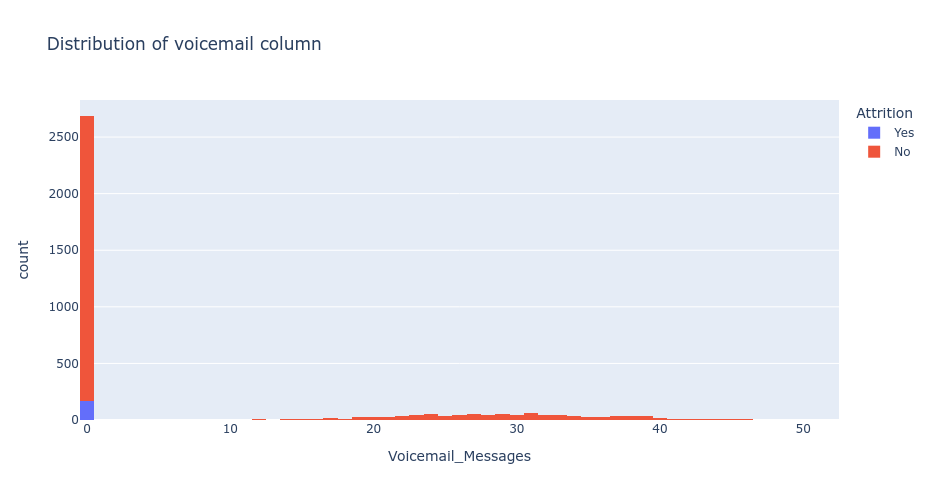

In [62]:
px.histogram(train_df,x='Voicemail_Messages',
             color = 'Attrition',
             title='Distribution of voicemail column',
            width = 800,height=500)

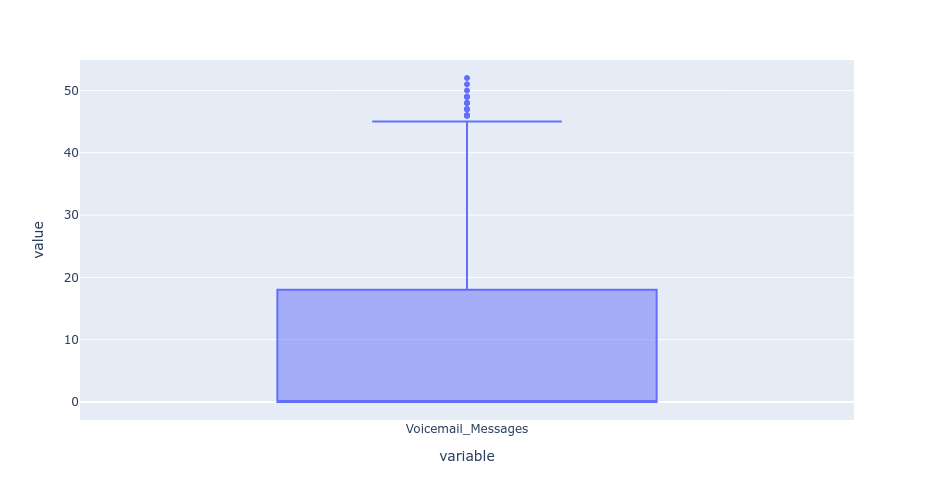

In [63]:
px.box(train_df['Voicemail_Messages'],
      width = 500,height=500)

from the graphs we see that most of the users never receive voicemail messages only a very small portion who receive voicemail messages

In [64]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

train_df['Voicemail_Messages'] = imputer.fit_transform(train_df[['Voicemail_Messages']])

In [65]:
train_df['Voicemail_Messages'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Voicemail_Messages
Non-Null Count  Dtype  
--------------  -----  
4150 non-null   float64
dtypes: float64(1)
memory usage: 32.6 KB


### 3. Day_Minutes column ###

In [66]:
train_df['Day_Minutes'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Day_Minutes
Non-Null Count  Dtype  
--------------  -----  
4150 non-null   float64
dtypes: float64(1)
memory usage: 32.6 KB


In [67]:
train_df['Day_Minutes'].describe()

count    4150.000000
mean      177.145687
std        51.396781
min         0.000000
25%       142.825000
50%       178.400000
75%       212.100000
max       351.500000
Name: Day_Minutes, dtype: float64

Text(0.5, 1.0, 'Distribution of Day Minutes Column')

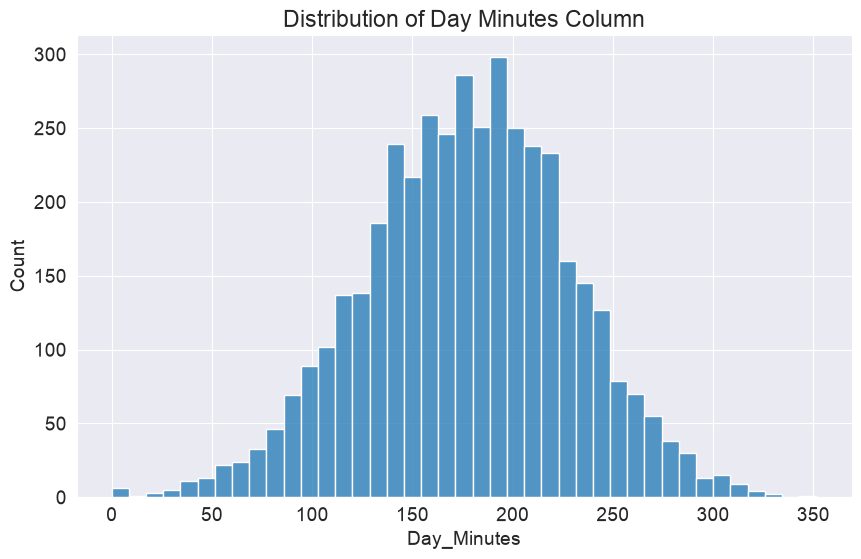

In [68]:
sns.histplot(data=train_df['Day_Minutes'])
plt.title('Distribution of Day Minutes Column')

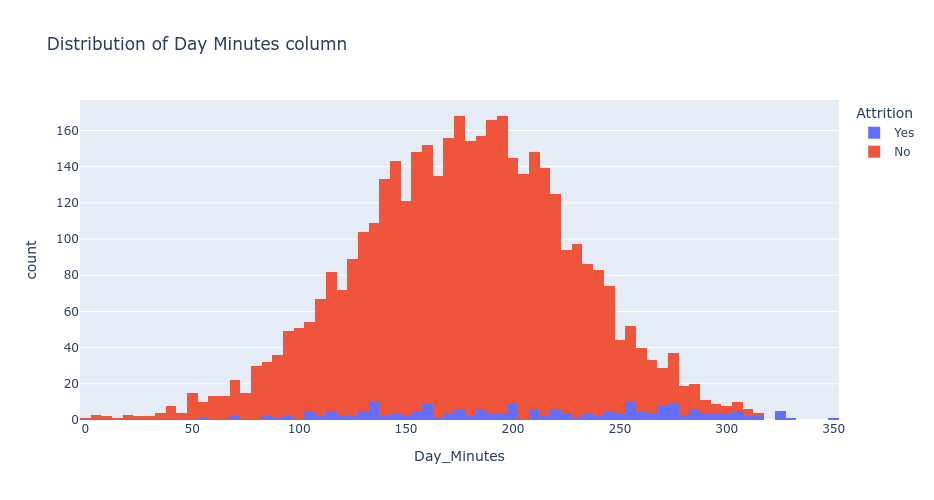

In [69]:
px.histogram(train_df,x='Day_Minutes',
             color = 'Attrition',
             title='Distribution of Day Minutes column',
            width = 800,height=500)

from the graph we can see that the day minutes column is normally distributed

### 4. Day_Calls column ###

In [70]:
train_df['Day_Calls'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Day_Calls
Non-Null Count  Dtype  
--------------  -----  
3640 non-null   float64
dtypes: float64(1)
memory usage: 32.6 KB


In [71]:
train_df['Day_Calls'].describe()

count    3640.000000
mean      100.010440
std        19.569463
min         0.000000
25%        87.000000
50%       100.000000
75%       113.000000
max       163.000000
Name: Day_Calls, dtype: float64

Text(0.5, 1.0, 'distribution of day calls')

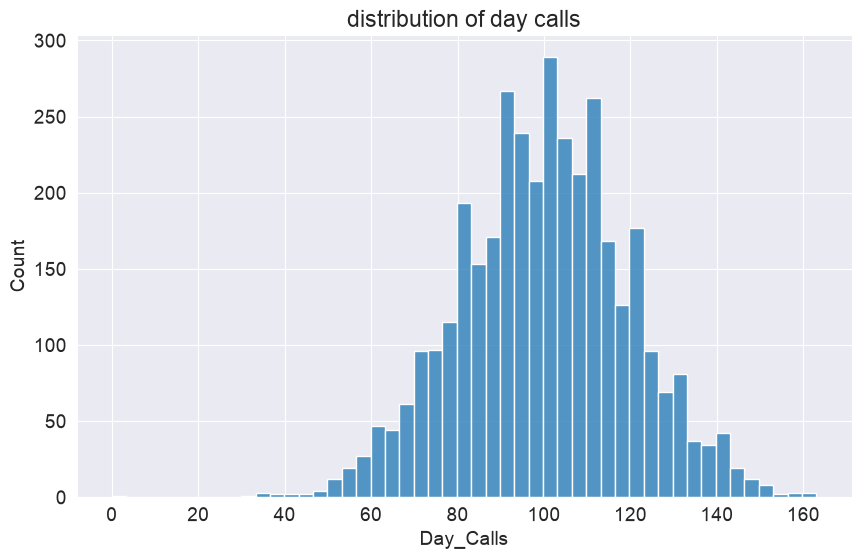

In [72]:
sns.histplot(data=train_df['Day_Calls'])
plt.title('distribution of day calls')

we can se also that the day calls column is normally distributed

In [73]:
train_df[['Day_Calls']] = imputer.fit_transform(train_df[['Day_Calls']])

### 5. Eve_Minutes columns ###

In [74]:
train_df['Eve_Minutes'].describe()

count    3626.000000
mean      199.429923
std        50.015577
min        22.300000
25%       165.125000
50%       199.800000
75%       232.900000
max       361.800000
Name: Eve_Minutes, dtype: float64

Text(0.5, 1.0, 'distribution of evening minutes column')

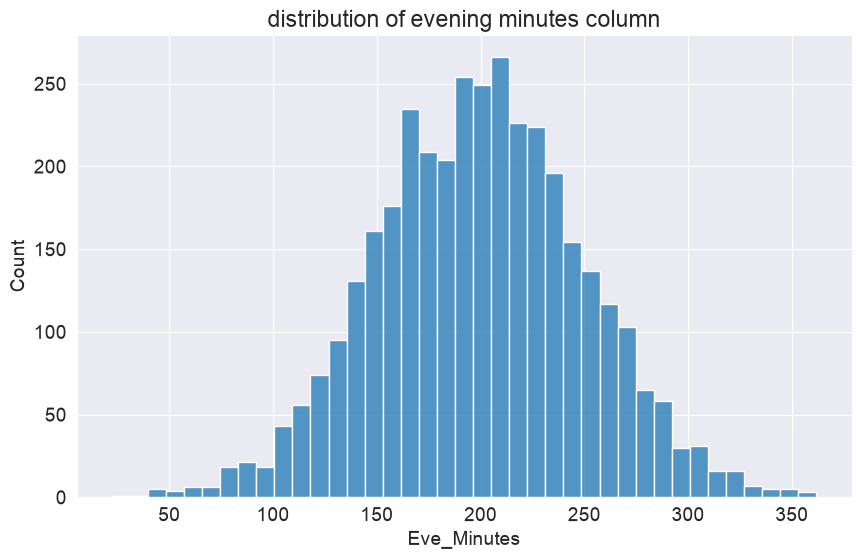

In [75]:
sns.histplot(data=train_df['Eve_Minutes'])
plt.title('distribution of evening minutes column')

In [76]:
train_df['Eve_Minutes'].isna().sum()

np.int64(524)

In [77]:
train_df['Eve_Minutes'] = imputer.fit_transform(train_df[['Eve_Minutes']])

In [78]:
train_df['Eve_Minutes'] .info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Eve_Minutes
Non-Null Count  Dtype  
--------------  -----  
4150 non-null   float64
dtypes: float64(1)
memory usage: 32.6 KB


### 6. Night_Minutes column ###

In [79]:
train_df['Night_Minutes'].describe()

count    3548.000000
mean      199.746167
std        50.492036
min         0.000000
25%       165.975000
50%       199.150000
75%       233.325000
max       395.000000
Name: Night_Minutes, dtype: float64

Text(0.5, 1.0, 'distribution of Night minutes column')

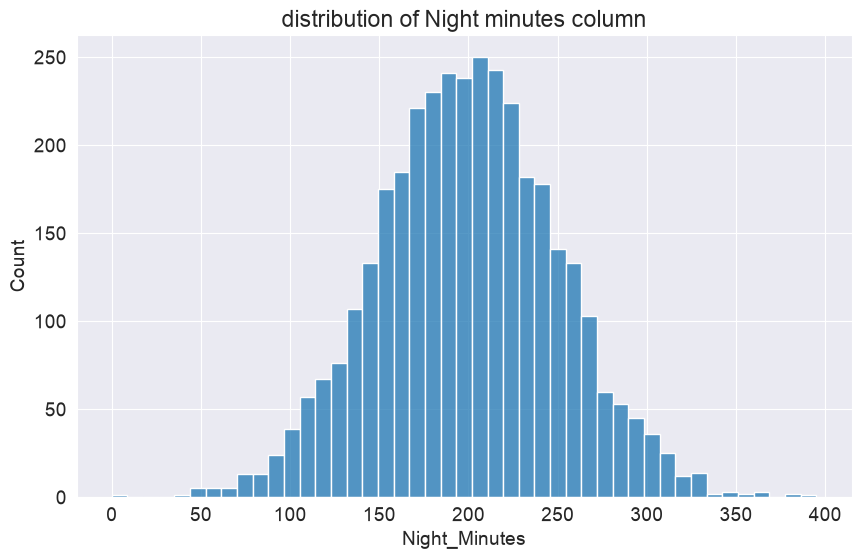

In [80]:
sns.histplot(data=train_df['Night_Minutes'])
plt.title('distribution of Night minutes column')

In [81]:
train_df['Night_Minutes'].isna().sum()

np.int64(602)

In [82]:
train_df['Night_Minutes'] = imputer.fit_transform(train_df[['Night_Minutes']])

In [83]:
train_df['Night_Minutes'].isna().sum()

np.int64(0)

### 7. Intl_Charge column ###

In [84]:
train_df['Intl_Charge'].info()

<class 'pandas.Series'>
RangeIndex: 4150 entries, 0 to 4149
Series name: Intl_Charge
Non-Null Count  Dtype  
--------------  -----  
3561 non-null   float64
dtypes: float64(1)
memory usage: 32.6 KB


In [85]:
train_df['Intl_Charge'].describe()

count    3561.000000
mean       35.851342
std         9.615616
min         0.000000
25%        29.900000
50%        36.140000
75%        42.120000
max        69.160000
Name: Intl_Charge, dtype: float64

Text(0.5, 1.0, 'distribution of international charges')

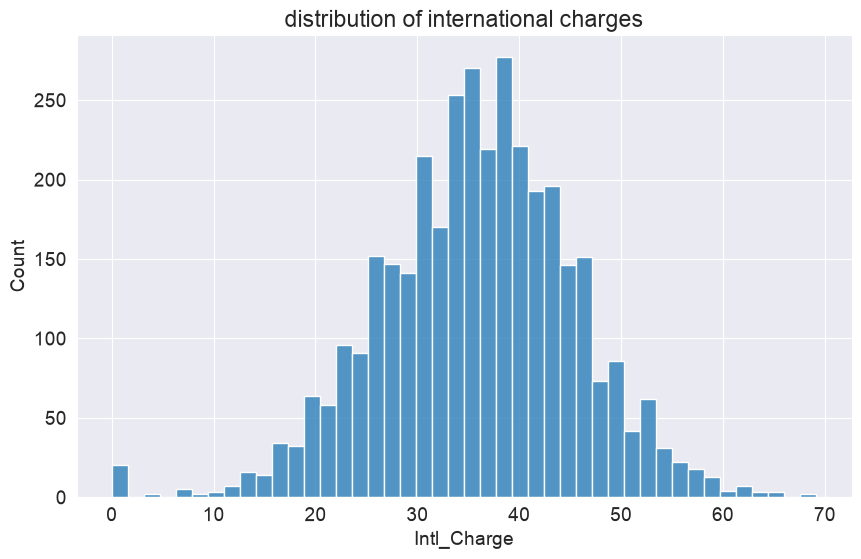

In [86]:
sns.histplot(train_df['Intl_Charge'])
plt.title('distribution of international charges')

In [87]:
train_df['Intl_Charge'].isna().sum()

np.int64(589)

In [88]:
train_df['Intl_Charge'] = imputer.fit_transform(train_df[['Intl_Charge']])

## Correlation Analysis ##

In [89]:
train_df.corr(numeric_only = True)

,Duration,Voicemail_Messages,Day_Minutes,Day_Calls,Day_Charge,Eve_Minutes,Eve_Calls,Eve_Charge,Night_Minutes,Night_Calls,Night_Charge,Intl_Minutes,Intl_Calls,Intl_Charge,Service_Calls,Age
Duration,1.000000,-0.016811,-0.013972,0.030327,-0.013974,0.002851,0.002685,-0.004202,0.004886,-0.008563,0.001359,-0.000318,0.008750,-0.002224,-0.008856,0.002683
Voicemail_Messages,-0.016811,1.000000,0.043315,0.006348,0.043312,0.018253,-0.000770,0.026448,0.012293,0.007010,0.020550,0.001458,-0.002591,0.003871,0.005680,-0.022243
Day_Minutes,-0.013972,0.043315,1.000000,0.008432,1.000000,-0.053079,0.002802,-0.062548,-0.012623,-0.002867,-0.013965,-0.031419,-0.026260,-0.019782,0.053861,-0.025220
Day_Calls,0.030327,0.006348,0.008432,1.000000,0.008435,-0.006385,-0.001399,-0.013409,0.005795,-0.007893,0.004056,0.012165,0.001191,0.021885,-0.011051,-0.011221
Day_Charge,-0.013974,0.043312,1.000000,0.008435,1.000000,-0.053077,0.002803,-0.062544,-0.012618,-0.002871,-0.013960,-0.031423,-0.026267,-0.019786,0.053851,-0.025205
Eve_Minutes,0.002851,0.018253,-0.053079,-0.006385,-0.053077,1.000000,-0.004570,0.932152,-0.009771,0.002897,-0.014091,-0.001391,0.013364,-0.006923,0.008679,0.017291
Eve_Calls,0.002685,-0.000770,0.002802,-0.001399,0.002803,-0.004570,1.000000,-0.001870,0.006900,-0.020312,0.006940,-0.000362,-0.004080,-0.003201,0.008184,-0.010624
Eve_Charge,-0.004202,0.026448,-0.062548,-0.013409,-0.062544,0.932152,-0.001870,1.000000,-0.016457,0.007030,-0.022906,0.001660,0.019697,-0.005035,0.003807,0.019255
Night_Minutes,0.004886,0.012293,-0.012623,0.005795,-0.012618,-0.009771,0.006900,-0.016457,1.000000,0.020579,0.919334,-0.005402,-0.021988,0.004617,0.007791,0.003718
Night_Calls,-0.008563,0.007010,-0.002867,-0.007893,-0.002871,0.002897,-0.020312,0.007030,0.020579,1.000000,0.030183,-0.013562,0.001633,-0.008281,-0.016757,0.010953


In [90]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4150 entries, 0 to 4149
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Job                 4150 non-null   str    
 1   Duration            4150 non-null   int64  
 2   Intl_Plan           4150 non-null   str    
 3   Voicemail_Plan      4150 non-null   str    
 4   Voicemail_Messages  4150 non-null   float64
 5   Day_Minutes         4150 non-null   float64
 6   Day_Calls           4150 non-null   float64
 7   Day_Charge          4150 non-null   float64
 8   Eve_Minutes         4150 non-null   float64
 9   Eve_Calls           4150 non-null   int64  
 10  Eve_Charge          4150 non-null   float64
 11  Night_Minutes       4150 non-null   float64
 12  Night_Calls         4150 non-null   int64  
 13  Night_Charge        4150 non-null   float64
 14  Intl_Minutes        4150 non-null   float64
 15  Intl_Calls          4150 non-null   int64  
 16  Intl_Charge      

## Data Preprocessing ##

In [91]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
scaler = MinMaxScaler()
encoder = OneHotEncoder(sparse_output = False)

### 1. scaling numerical columns ###

In [92]:
train_df[numerical] = scaler.fit_transform(train_df[numerical])
test_df[numerical] = scaler.fit_transform(test_df[numerical])

### 2.encoding categorical columns ###

In [93]:
categorical = train_df.select_dtypes('str').columns.to_list()

In [94]:
categorical = categorical[1:3]

In [95]:
categorical

['Intl_Plan', 'Voicemail_Plan']

In [96]:
encoder.fit_transform(train_df[categorical])

array([[1., 0., 1., 0.],
       [1., 0., 1., 0.],
       [0., 1., 1., 0.],
       ...,
       [1., 0., 1., 0.],
       [1., 0., 1., 0.],
       [1., 0., 0., 1.]], shape=(4150, 4))

In [97]:
encoded = encoder.get_feature_names_out()

In [98]:
test_df[encoded] = encoder.fit_transform(test_df[categorical])

In [99]:
train_df[encoded] = encoder.fit_transform(train_df[categorical])

## Model Training ##

In [100]:
X_train = pd.concat([train_df[numerical],train_df[encoded]],axis = 1)

In [101]:
X_train

,Duration,Voicemail_Messages,Day_Minutes,Day_Calls,Day_Charge,Eve_Minutes,Eve_Calls,Eve_Charge,Night_Minutes,Night_Calls,Night_Charge,Intl_Minutes,Intl_Calls,Intl_Charge,Service_Calls,Intl_Plan_no,Intl_Plan_yes,Voicemail_Plan_no,Voicemail_Plan_yes
0,0.161157,0.000000,0.880228,0.527607,0.880187,0.733432,0.576471,0.749919,0.498987,0.662857,0.499156,0.568528,0.263158,0.567669,0.375,1.0,0.0,1.0,0.0
1,0.661157,0.000000,0.454054,0.625767,0.453983,0.560530,0.700000,0.587642,0.383291,0.474286,0.383230,0.639594,0.368421,0.522556,0.625,1.0,0.0,1.0,0.0
2,0.280992,0.000000,0.502987,0.613497,0.503012,0.511635,0.523529,0.541789,0.588861,0.862857,0.589195,0.664975,0.263158,0.522556,0.125,0.0,1.0,1.0,0.0
3,0.466942,0.000000,0.328876,0.570552,0.328815,0.522828,0.458824,0.451057,0.636203,0.594286,0.636466,0.492386,0.052632,0.492481,0.250,0.0,1.0,1.0,0.0
4,0.425620,0.000000,0.743101,0.496933,0.742972,0.550221,0.764706,0.577886,0.711646,0.691429,0.711874,0.573604,0.052632,0.573308,0.250,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4145,0.305785,0.000000,0.485633,0.619632,0.485609,0.503093,0.741176,0.533659,0.326835,0.594286,0.326956,0.350254,0.368421,0.522556,0.125,1.0,0.0,1.0,0.0
4146,0.202479,0.769231,0.670555,0.779141,0.670515,0.522828,0.741176,0.616585,0.753165,0.662857,0.753517,0.502538,0.263158,0.522556,0.250,1.0,0.0,0.0,1.0
4147,0.247934,0.000000,0.400000,0.546012,0.399933,0.443299,0.752941,0.477724,0.537722,0.554286,0.537985,0.690355,0.210526,0.689850,0.125,1.0,0.0,1.0,0.0
4148,0.446281,0.000000,0.537127,0.411043,0.537149,0.440059,0.541176,0.474472,0.568101,0.508571,0.568374,0.431472,0.315789,0.432331,0.000,1.0,0.0,1.0,0.0


In [102]:
X_train_target = train_df[target_col]

In [103]:
X_train_target.value_counts()

Attrition
No     3943
Yes     207
Name: count, dtype: int64

In [104]:
X_test = pd.concat([test_df[numerical],test_df[encoded]], axis = 1)

In [105]:
X_test

,Duration,Voicemail_Messages,Day_Minutes,Day_Calls,Day_Charge,Eve_Minutes,Eve_Calls,Eve_Charge,Night_Minutes,Night_Calls,Night_Charge,Intl_Minutes,Intl_Calls,Intl_Charge,Service_Calls,Intl_Plan_no,Intl_Plan_yes,Voicemail_Plan_no,Voicemail_Plan_yes
0,0.285714,0.000000,0.368016,0.830303,0.368042,0.593383,0.303279,0.593418,0.482944,0.594828,0.483378,0.635,0.30,0.635185,0.444444,1.0,0.0,1.0,0.0
1,0.714286,0.000000,0.948974,0.406061,0.948860,0.861955,0.418033,0.861996,0.338719,0.741379,0.339096,0.270,0.45,0.270370,0.444444,1.0,0.0,1.0,0.0
2,0.339286,0.000000,0.177879,0.539394,0.177901,0.417143,0.614754,0.417197,0.485338,0.189655,0.485372,0.285,0.30,0.285185,0.555556,1.0,0.0,1.0,0.0
3,0.049107,0.000000,0.711517,0.715152,0.711435,0.665263,0.598361,0.665251,0.696589,0.413793,0.696809,0.590,0.15,0.590741,0.111111,1.0,0.0,1.0,0.0
4,0.598214,0.854167,0.493444,0.515152,0.493461,0.519398,0.500000,0.519462,0.223818,0.310345,0.224069,0.730,0.75,0.729630,0.000000,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
845,0.433036,0.645833,0.344926,0.636364,0.344903,0.564511,0.426230,0.564756,0.536505,0.586207,0.536569,0.600,0.05,0.600000,0.111111,1.0,0.0,0.0,1.0
846,0.325893,0.000000,0.630274,0.751515,0.630282,0.239398,0.393443,0.239561,0.576601,0.603448,0.576463,0.530,0.15,0.529630,0.000000,1.0,0.0,1.0,0.0
847,0.424107,0.541667,0.415621,0.654545,0.415661,0.484211,0.352459,0.484430,0.352184,0.465517,0.352394,0.495,0.10,0.494444,0.111111,1.0,0.0,0.0,1.0
848,0.526786,0.000000,0.635120,0.739394,0.635144,0.396992,0.500000,0.397028,0.338719,0.603448,0.339096,0.560,0.30,0.559259,0.111111,1.0,0.0,1.0,0.0


# Classification using Logistic Regression #

In [106]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [107]:
logreg = LogisticRegression(solver='liblinear')

In [108]:
logreg.fit(X_train, X_train_target)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [109]:
logreg.score(X_train,X_train_target)

0.952289156626506

In [110]:
train_preds = logreg.predict(X_train)

In [111]:
cf = confusion_matrix(X_train_target,train_preds,normalize='true')

In [112]:
logreg.classes_

array(['No', 'Yes'], dtype=object)

<Axes: >

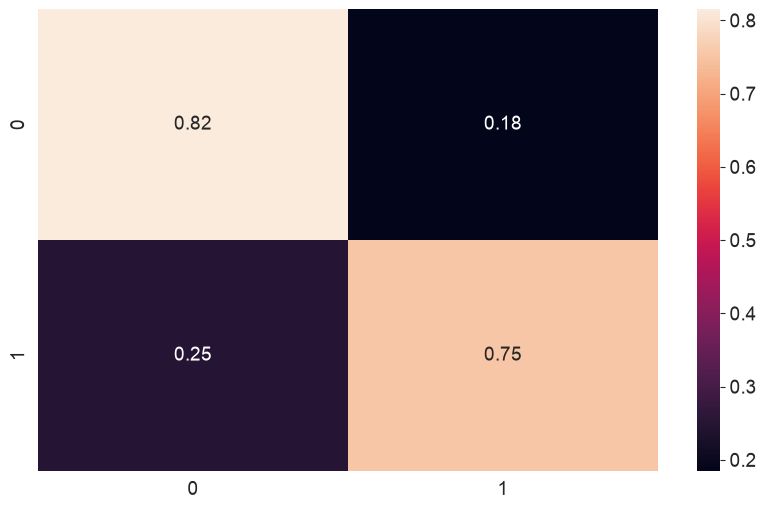

In [173]:
sns.heatmap(cf, annot = True)

#### we can see that our model performs poorly on predicting the 'Yes' class due to class imbalance in the target, we can perform tuning to improve its performance ####

In [114]:
def random_guess(inputs):
    return np.random.choice(['No','Yes'],len(inputs))

In [115]:
def all_no(inputs):
    return np.full(len(inputs), 'No')

In [116]:
accuracy_score(X_train_target, random_guess(X_train))

0.5028915662650603

In [117]:
accuracy_score(X_train_target, all_no(X_train))

0.9501204819277108

## Hyperparameter Tuning and Generalization of Logistic Regression Model ##

In [118]:
logreg = LogisticRegression(solver='liblinear', class_weight = {'No':1,'Yes':15}, max_iter = 500)

In [119]:
logreg.fit(X_train, X_train_target)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{'No': 1, 'Yes': 15}"
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularizat

In [120]:
logreg.score(X_train, X_train_target)

0.812289156626506

In [121]:
train_preds = logreg.predict(X_train)

In [122]:
cf = confusion_matrix(X_train_target,train_preds,normalize='true')

In [123]:
cf

array([[0.81536901, 0.18463099],
       [0.24637681, 0.75362319]])

Text(0.5, 1.0, 'Logistic Regression Confusion Matrix of Training set')

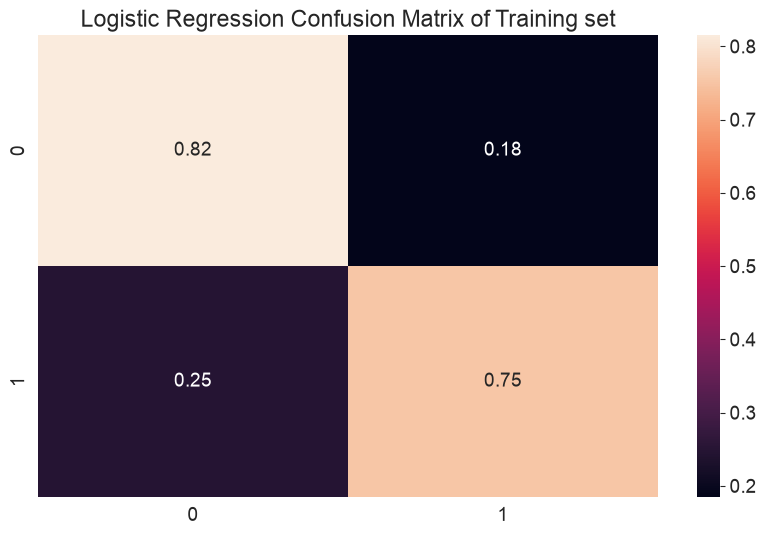

In [174]:
sns.heatmap(cf, annot = True)
plt.title('Logistic Regression Confusion Matrix of Training set')

In [125]:
print(classification_report(X_train_target,train_preds))

              precision    recall  f1-score   support

          No       0.98      0.82      0.89      3943
         Yes       0.18      0.75      0.29       207

    accuracy                           0.81      4150
   macro avg       0.58      0.78      0.59      4150
weighted avg       0.94      0.81      0.86      4150



In [126]:
TP = cf[0,0]
TN = cf[1,1]
FP = cf[0,1]
FN = cf[1,0]

### Classification accuracy ###

In [127]:
classification_accuracy = (TP + TN)/float(TP + TN + FP + FN)
print('classification accuracy is {0:0.2f}'.format(classification_accuracy))

classification accuracy is 0.78


### Classification error ###

In [128]:
classification_error = (FP + FN)/float(TP + TN + FP + FN)
print('classification error is {0:0.2f}'.format(classification_error))

classification error is 0.22


### Precision ###

In [129]:
precision = TP/(TP + FP)
print('precision is {0:0.2f}'.format(precision))

precision is 0.82


### Recall ###

In [130]:
recall = TP/(TP + FN)
print('recall is {0:0.2f}'.format(recall))

recall is 0.77


### Generalization ###

In [131]:
test_preds = logreg.predict(X_test)

In [132]:
raw_test_df['Attrition'] = test_preds

In [133]:
raw_test_df[['User ID','Attrition']].to_csv('first.csv',index = False)

# Classification using Desicion trees #

In [134]:
from sklearn.model_selection import train_test_split
X_train,X_val = train_test_split(X_train,test_size = 0.2, random_state = 10)
X_train_target,X_val_target = train_test_split(X_train_target,test_size = 0.2, random_state = 10)

In [135]:
from sklearn.tree import DecisionTreeClassifier

In [136]:
dt = DecisionTreeClassifier(random_state=10)

In [137]:
dt.fit(X_train,X_train_target)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [138]:
dt_preds = dt.predict(X_train)

In [139]:
dt.score(X_train,X_train_target)

1.0

In [140]:
cmt = confusion_matrix(X_train_target,dt_preds,normalize = 'true')

<Axes: title={'center': 'Decision trees training confusion matrix'}>

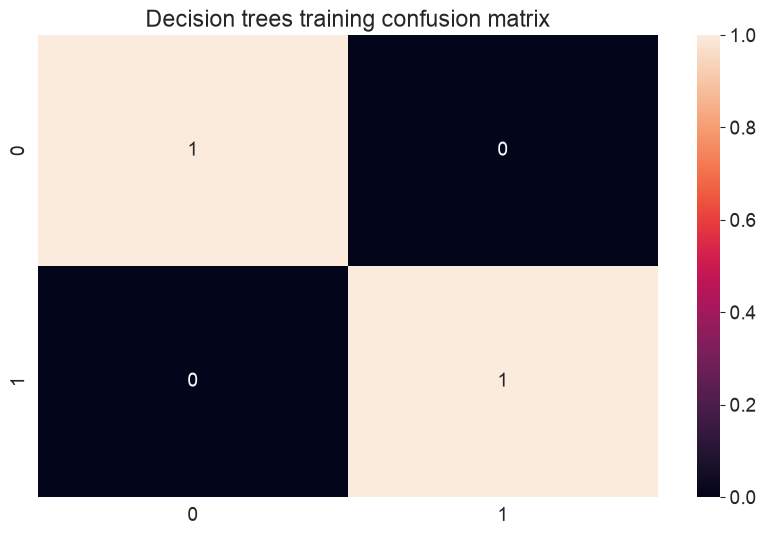

In [175]:
plt.title('Decision trees training confusion matrix')
sns.heatmap(cmt,annot = True)

In [142]:
dt.score(X_val,X_val_target)

0.9421686746987952

In [143]:
preds_val = dt.predict(X_val)

In [144]:
cmv = confusion_matrix(X_val_target,preds_val,normalize = 'true')

<Axes: title={'center': 'Decision trees validating confusion matrix'}>

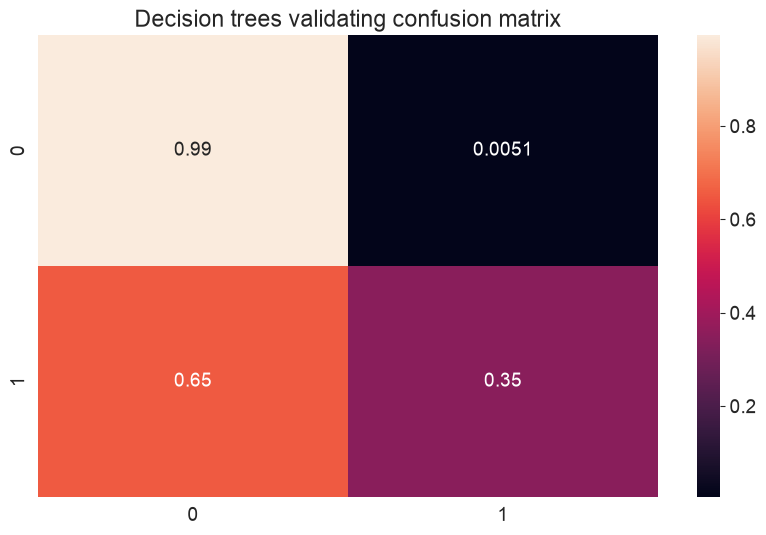

In [176]:
plt.title('Decision trees validating confusion matrix')
sns.heatmap(cmv,annot = True)

we can see that our model is overfitted now we must do some regularization through hyperparameter tuning

## Hyperparameter tuning, regularization and Generalization ##

In [146]:
def test_params(**params):
    dt = DecisionTreeClassifier(random_state=10,**params)
    dt.fit(X_train,X_train_target)
    preds_train = dt.predict(X_train)
    preds_val = dt.predict(X_val)
    train_acc = dt.score(X_train,X_train_target)
    val_acc = dt.score(X_val, X_val_target)
    crt = classification_report(X_train_target,preds_train)
    crv = classification_report(X_val_target,preds_val)
    cmt = confusion_matrix(X_train_target,dt_preds,normalize = 'true')
    cmv = confusion_matrix(X_val_target,preds_val,normalize = 'true')
    plt.subplot(2,2,1)
    hmt = sns.heatmap(cmt,annot = True)
    plt.subplot(2,2,2)
    hmv = sns.heatmap(cmv,annot = True)
    return print('training accuracy is {}'.format(train_acc)),print('validating accuracy is {}'.format(val_acc)),hmt,hmv,print(crt),print(crv)

training accuracy is 0.9966867469879518
validating accuracy is 0.9518072289156626
              precision    recall  f1-score   support

          No       1.00      1.00      1.00      3156
         Yes       0.94      0.99      0.97       164

    accuracy                           1.00      3320
   macro avg       0.97      1.00      0.98      3320
weighted avg       1.00      1.00      1.00      3320

              precision    recall  f1-score   support

          No       0.98      0.97      0.97       787
         Yes       0.53      0.56      0.55        43

    accuracy                           0.95       830
   macro avg       0.75      0.77      0.76       830
weighted avg       0.95      0.95      0.95       830



(None, None, <Axes: >, <Axes: >, None, None)

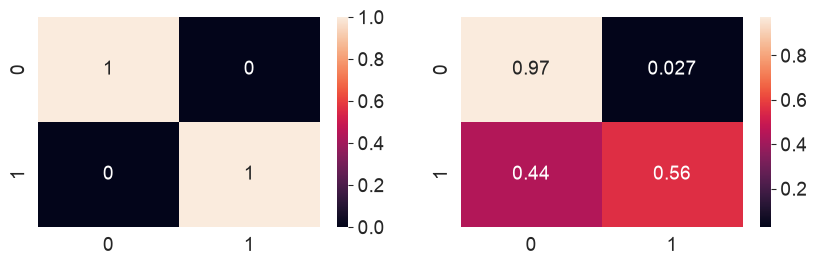

In [147]:
test_params(class_weight = {'No':1,'Yes':3},ccp_alpha=0.0005)

we managed to reduce increase the accuracy of the validating set from 94.2% to 95.1% so our model has learned a little

## Generalization ##

In [148]:
dt = DecisionTreeClassifier(random_state=10,class_weight = {'No':1,'Yes':3},ccp_alpha=0.0005)

In [149]:
dt.fit(X_train,X_train_target)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",10
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{'No': 1, 'Yes': 3}"
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.0005
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of 

In [150]:
test_preds = dt.predict(X_test)

In [151]:
raw_test_df['Attrition'] = test_preds

In [152]:
raw_test_df[['User ID','Attrition']].to_csv('second.csv',index = False)

# Classification using Random Forest #

In [153]:
from sklearn.ensemble import RandomForestClassifier
ranfor = RandomForestClassifier(random_state = 10, n_jobs = -1)

In [154]:
ranfor.fit(X_train,X_train_target)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",10
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [155]:
train_preds = ranfor.predict(X_train)

In [156]:
val_preds = ranfor.predict(X_val)

In [157]:
ranfor.score(X_train,X_train_target)

1.0

In [158]:
ranfor.score(X_val,X_val_target)

0.9614457831325302

In [159]:
cmt = confusion_matrix(X_train_target,train_preds,normalize = 'true')

In [160]:
cmv = confusion_matrix(X_val_target,val_preds,normalize = 'true')

<Axes: title={'center': 'Random Trees training confusion matrix'}>

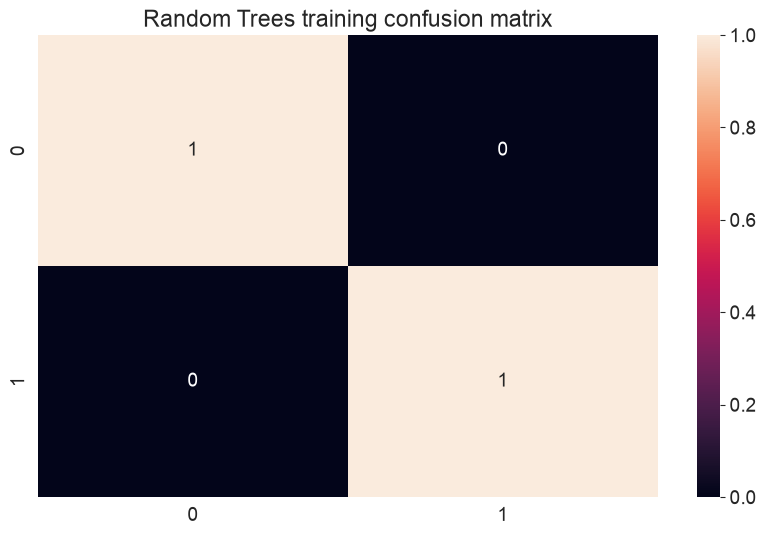

In [177]:
plt.title('Random Trees training confusion matrix')
sns.heatmap(cmt,annot = True)

<Axes: title={'center': 'Random Trees validating confusion matrix'}>

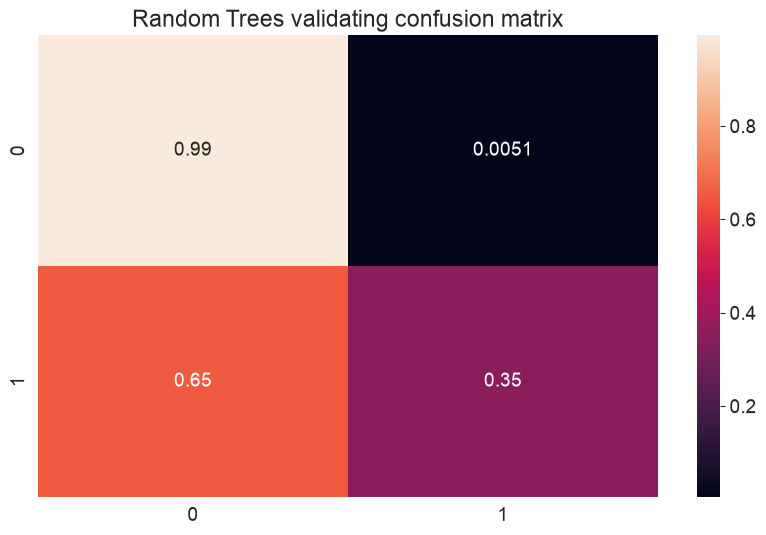

In [178]:
plt.title('Random Trees validating confusion matrix')
sns.heatmap(cmv,annot = True)

also in random forest, we see that our model is overfitted now we must do some regularization through hyperparameter tuning

## Hyperparameter tuning, regularization and Generalization in Random Forest ##

In [163]:
def params(**params):
    ranfor = RandomForestClassifier(random_state=10,**params)
    ranfor.fit(X_train,X_train_target)
    preds_train = ranfor.predict(X_train)
    preds_val = ranfor.predict(X_val)
    train_acc = dt.score(X_train,X_train_target)
    val_acc = dt.score(X_val, X_val_target)
    crt = classification_report(X_train_target,preds_train)
    crv = classification_report(X_val_target,preds_val)
    cmt = confusion_matrix(X_train_target,dt_preds,normalize = 'true')
    cmv = confusion_matrix(X_val_target,preds_val,normalize = 'true')
    plt.subplot(2,2,1)
    hmt = sns.heatmap(cmt,annot = True)
    plt.subplot(2,2,2)
    hmv = sns.heatmap(cmv,annot = True)
    return print('training accuracy is {}'.format(train_acc)),print('validating accuracy is {}'.format(val_acc)),hmt,hmv,print(crt),print(crv)

training accuracy is 0.9966867469879518
validating accuracy is 0.9518072289156626
              precision    recall  f1-score   support

          No       1.00      1.00      1.00      3156
         Yes       0.99      0.99      0.99       164

    accuracy                           1.00      3320
   macro avg       1.00      1.00      1.00      3320
weighted avg       1.00      1.00      1.00      3320

              precision    recall  f1-score   support

          No       0.97      0.99      0.98       787
         Yes       0.78      0.49      0.60        43

    accuracy                           0.97       830
   macro avg       0.88      0.74      0.79       830
weighted avg       0.96      0.97      0.96       830



(None, None, <Axes: >, <Axes: >, None, None)

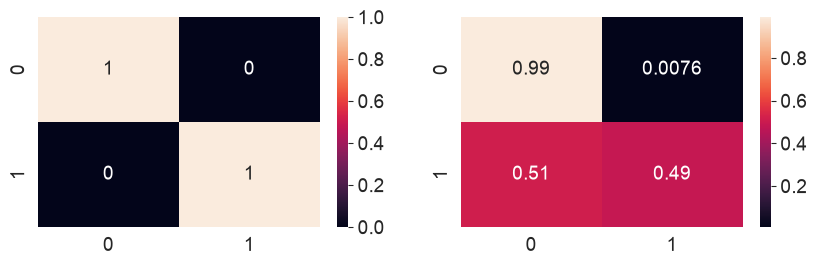

In [164]:
params(class_weight ={'No':1,'Yes':3}
       ,ccp_alpha=0.0005)

#### After trying to tune different hyperparameters to improve the model, all parameters didnt have effect on the model, this maybe due to the small size of the dataset which leads to highly overfitting ####

### Generalization ###

In [168]:
ranfor = RandomForestClassifier(random_state=10,class_weight ={'No':1,'Yes':3},ccp_alpha=0.0005)

In [169]:
ranfor.fit(X_train,X_train_target)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",10
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{'No': 1, 'Yes': 3}"
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",0.0005
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, d

In [170]:
test_preds = ranfor.predict(X_test)

In [171]:
raw_test_df['Attrition'] = test_preds

In [172]:
raw_test_df[['User ID','Attrition']].to_csv('third.csv')